# Imports & Adaptive Logic

In [25]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os

sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from feature_eng import DataProcessor
from model import RULPredictor

# --- ADAPTIVE INPUT LOGIC ---
# Defined here to ensure reproducibility within the notebook
def prepare_adaptive_input(bat_data, processor, window_size=30):
    feature_values = bat_data[processor.feature_columns].values
    target_values = bat_data[processor.target_column].values
    X_sequences, y_targets = [], []
    
    for i in range(len(bat_data)):
        if i < window_size:
            # Cold Start Problem: Not enough history
            # Solution: Edge Padding (Repeat the first available data)
            available_data = feature_values[0 : i+1]
            missing_len = window_size - len(available_data)
            first_row = available_data[0].reshape(1, -1)
            padding = np.repeat(first_row, missing_len, axis=0)
            window = np.vstack((padding, available_data))
        else:
            # Standard Sliding Window
            window = feature_values[i - window_size + 1 : i + 1]
        
        X_sequences.append(window)
        y_targets.append(target_values[i])
        
    return np.array(X_sequences), np.array(y_targets)

print(" Adaptive Input Logic Loaded.")

 Adaptive Input Logic Loaded.


# Model & Data Loading

In [29]:
# Setup
DEVICE = torch.device("cpu") # CPU is sufficient for inference
processor = DataProcessor()

# Load Data
if os.path.exists("../data/processed/final_features.csv"):
    feat_df = pd.read_csv("../data/processed/final_features.csv")
else:
    print("Error: Processed data not found.")

# Load Model
model = RULPredictor(input_dim=4, hidden_dim=64).to(DEVICE)

# Try loading the notebook trained model first, else the src trained model
model_path = "../models/best_model_notebook.pth"
if not os.path.exists(model_path):
    model_path = "../models/best_model.pth"

if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.eval()
    print(f" Model loaded from {model_path}")
else:
    print(" No model found! Run Notebook 02 first.")

 Model loaded from ../models/best_model_notebook.pth


# The "Money Shot" (B0032 Adaptive Prediction)

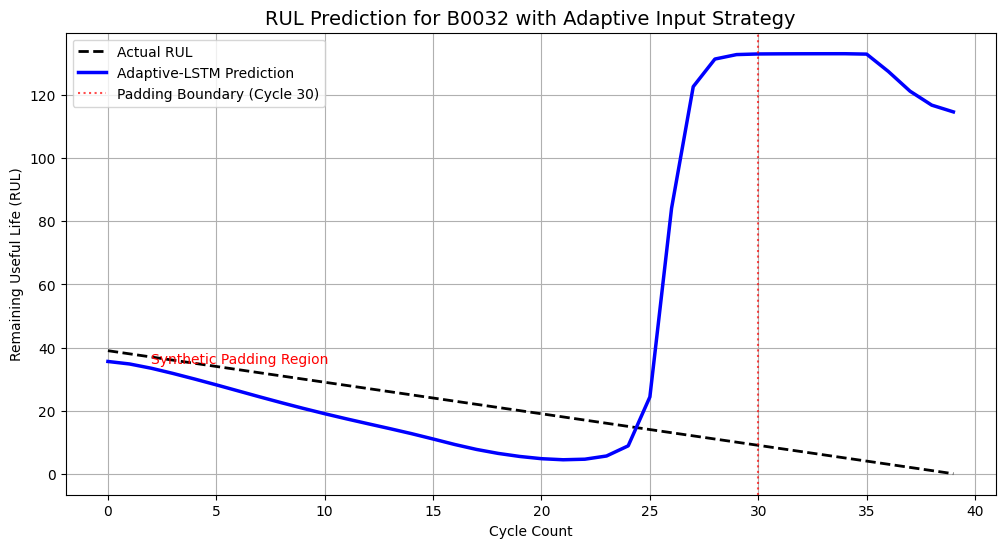

In [31]:
# Test on Problematic Battery B0032 (High Temperature)
bat_id = 'B0032'
subset = feat_df[feat_df['battery_id'] == bat_id]

if not subset.empty:
    # Scale Data (Using fit_transform for visualization demo)
    # Note: In production, use the scaler fitted on training data
    subset_scaled = subset.copy()
    subset_scaled[processor.feature_columns] = processor.scaler.fit_transform(subset[processor.feature_columns])

    # Prepare Adaptive Input
    X_adaptive, y_true = prepare_adaptive_input(subset_scaled, processor)
    X_tensor = torch.FloatTensor(X_adaptive).to(DEVICE)

    # Predict
    with torch.no_grad():
        preds, attn_weights = model(X_tensor)
    preds = preds.numpy()

    # Visualization
    plt.figure(figsize=(12, 6))
    plt.plot(y_true, label='Actual RUL', color='black', linestyle='--', linewidth=2)
    plt.plot(preds, label='Adaptive-LSTM Prediction', color='blue', linewidth=2.5)

    # Highlight Padding Zone
    plt.axvline(x=30, color='red', linestyle=':', alpha=0.7, label='Padding Boundary (Cycle 30)')
    plt.text(2, np.max(y_true)*0.9, 'Synthetic Padding Region', color='red')

    plt.title(f'RUL Prediction for {bat_id} with Adaptive Input Strategy', fontsize=14)
    plt.xlabel('Cycle Count')
    plt.ylabel('Remaining Useful Life (RUL)')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print(f"Battery {bat_id} not found in dataset.")

# Explainable AI (Attention Heatmap)

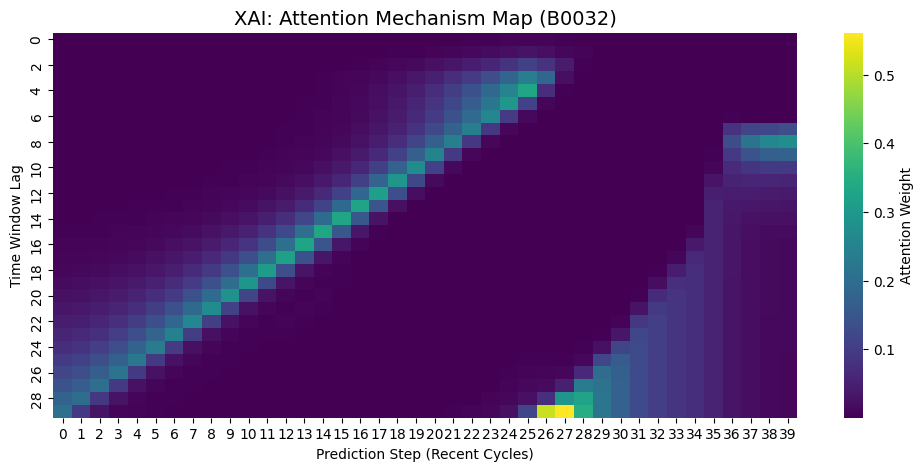

Interpretation: Brighter colors indicate time steps that strongly influenced the RUL prediction.


In [33]:
# Visualize Attention for the last 50 cycles
if 'attn_weights' in locals():
    subset_size = 50
    if len(attn_weights) > subset_size:
        attn_map = attn_weights[-subset_size:].squeeze().T
    else:
        attn_map = attn_weights.squeeze().T

    plt.figure(figsize=(12, 5))
    sns.heatmap(attn_map, cmap='viridis', cbar_kws={'label': 'Attention Weight'})
    plt.title(f'XAI: Attention Mechanism Map ({bat_id})', fontsize=14)
    plt.xlabel('Prediction Step (Recent Cycles)')
    plt.ylabel('Time Window Lag')
    plt.show()
    print("Interpretation: Brighter colors indicate time steps that strongly influenced the RUL prediction.")